C:\Users\youss\AppData\Roaming\Python\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


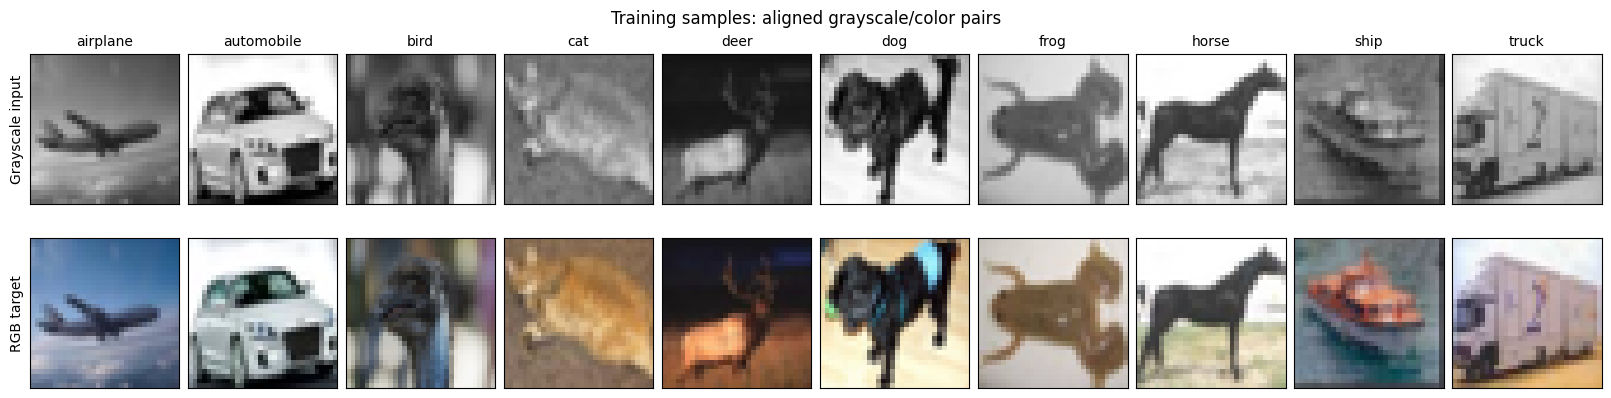

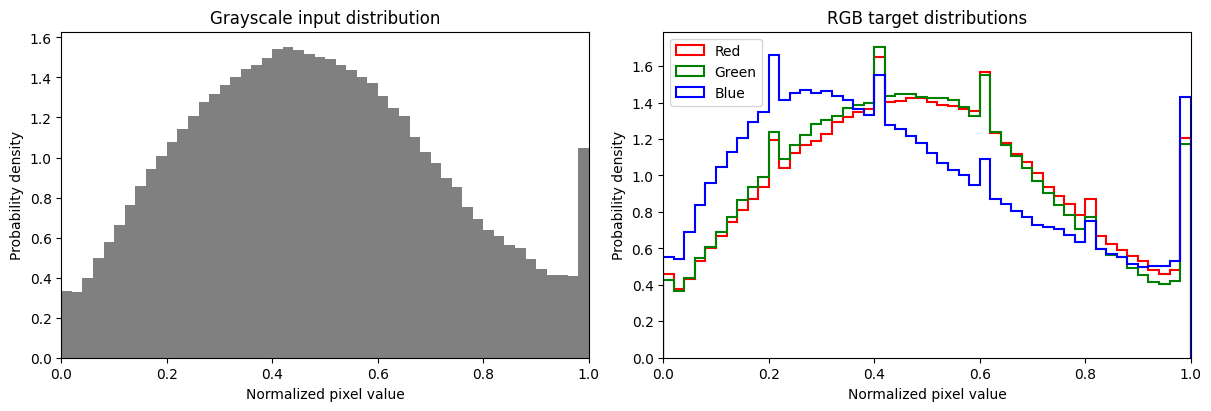

Dataset: balanced CIFAR-10 subset, 5,000 images, 32x32 RGB
Training: X=(3500, 1024), Y=(3500, 3072); per-class counts=[350 350 350 350 350 350 350 350 350 350]
Validation: X=(1000, 1024), Y=(1000, 3072); per-class counts=[100 100 100 100 100 100 100 100 100 100]
Testing: X=(500, 1024), Y=(500, 3072); per-class counts=[50 50 50 50 50 50 50 50 50 50]
Training batches: 35, batch size: 100
Grayscale range: [0.0000, 1.0000]
RGB range: [0.0000, 1.0000]


In [1]:
#1
#Dataset, Preprocessing, and Splitting
#Choose CIFAR-10, normalize and visualize grayscale/RGB pairs, split 70/20/10, and create batches of 100.

import numpy as np
import matplotlib.pyplot as plt
import kagglehub
import pickle
from pathlib import Path

# Dataset documentation: https://keras.io/api/datasets/cifar10/

SEED = 42
SAMPLES_PER_CLASS = 500
IMAGE_SIZE = 32
BATCH_SIZE = 100
rng = np.random.default_rng(SEED)
class_names = np.array([
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
])

# Load CIFAR-10 through KaggleHub / Colab's dataset cache.
# Use the original training pool only; create our own 70/20/10 splits below.
path = kagglehub.dataset_download("pankrzysiu/cifar10-python")
batch_files = sorted(Path(path).rglob("data_batch_*")) # Sort all batch files
assert len(batch_files) == 5, f"Expected 5 training files in {path}"

image_parts, label_parts = [], []
for file in batch_files:
    with open(file, "rb") as f:
        batch = pickle.load(f, encoding="bytes")
    image_parts.append(batch[b"data"])
    label_parts.extend(batch[b"labels"])

# CIFAR stores channels separately; convert to (images, height, width, RGB).
source_rgb = (
    np.concatenate(image_parts)
    .reshape(-1, 3, IMAGE_SIZE, IMAGE_SIZE)
    .transpose(0, 2, 3, 1)
)
source_labels = np.array(label_parts)
del image_parts, label_parts, batch # Delete unwanted read files. We already copied them over

# Select 500 distinct images per class: a balanced 5,000-image working dataset.
selected_indices = np.concatenate([
    rng.choice(np.flatnonzero(source_labels == c), SAMPLES_PER_CLASS, replace=False)
    for c in range(len(class_names))
])
rng.shuffle(selected_indices)
labels = source_labels[selected_indices]

# Convert uint8 pixels to float32 in [0, 1].
color_images = source_rgb[selected_indices].astype(np.float32) / 255.0
del source_rgb, source_labels #Delete unwanted files.

# Standard weighted RGB-to-grayscale conversion (BT.601 luma weights).
# Each grayscale image and its RGB target remain at the same array index.
gray_images = color_images @ np.array([0.299, 0.587, 0.114], dtype=np.float32)

# Split within each class: 350 train, 100 validation, 50 test images.
# Fixed seeds make selection and splitting reproducible; no image crosses splits.
train_parts, val_parts, test_parts = [], [], []
for c in range(len(class_names)):
    indices = np.flatnonzero(labels == c)
    rng.shuffle(indices)
    n_train = int(0.70 * len(indices))
    n_val = int(0.20 * len(indices))
    train_parts.append(indices[:n_train])
    val_parts.append(indices[n_train:n_train + n_val])
    test_parts.append(indices[n_train + n_val:])

train_idx = rng.permutation(np.concatenate(train_parts))
val_idx = rng.permutation(np.concatenate(val_parts))
test_idx = rng.permutation(np.concatenate(test_parts))

# X contains 5000 grayscale images, each with 1024 grayscale values.
# Y contains 5000 rgb images, each with 3072 RGB target values.
# X[0,0] returns gray intensity of pixel 0 in image 0.
# Y[0,0] returns red intensity of pixel 0 in image 0, Y[0,1] = green pixel 0,
# Y[0,2] = blue pixel 0, and eg. Y[0,5] = blue pixel 1; X[0,1] = gray pixel 1.
X = gray_images.reshape(len(labels), IMAGE_SIZE * IMAGE_SIZE)
Y = color_images.reshape(len(labels), IMAGE_SIZE * IMAGE_SIZE * 3)
X_train, Y_train = X[train_idx], Y[train_idx]
X_val, Y_val = X[val_idx], Y[val_idx]
X_test, Y_test = X[test_idx], Y[test_idx]
labels_train, labels_val, labels_test = labels[train_idx], labels[val_idx], labels[test_idx]

# Sanity-check normalization, pairing, exact proportions, and unique membership.
assert X.dtype == Y.dtype == np.float32
assert np.isfinite(X).all() and np.isfinite(Y).all()
assert 0 <= X.min() <= X.max() <= 1
assert 0 <= Y.min() <= Y.max() <= 1
assert len(np.unique(selected_indices)) == 5000
assert len(np.unique(np.concatenate([train_idx, val_idx, test_idx]))) == 5000
assert (len(train_idx), len(val_idx), len(test_idx)) == (3500, 1000, 500)
assert np.allclose(X_train.reshape(-1, IMAGE_SIZE, IMAGE_SIZE),
                   Y_train.reshape(-1, IMAGE_SIZE, IMAGE_SIZE, 3) @ np.array([0.299, 0.587, 0.114], dtype=np.float32))

# Show one training example per class. Keep validation/test images for later use.
fig, axes = plt.subplots(2, 10, figsize=(16, 4), constrained_layout=True)
for c in range(len(class_names)):
    display_index = np.random.default_rng().integers(0, 350)
    i = train_idx[np.flatnonzero(labels_train == c)[display_index]]
    axes[0, c].imshow(gray_images[i], cmap='gray', vmin=0, vmax=1)
    axes[1, c].imshow(color_images[i])
    axes[0, c].set_title(class_names[c], fontsize=10)
    for row in range(2):
        axes[row, c].set_xticks([])
        axes[row, c].set_yticks([])
axes[0, 0].set_ylabel('Grayscale input')
axes[1, 0].set_ylabel('RGB target')
fig.suptitle('Training samples: aligned grayscale/color pairs')
plt.show()

# Plot training pixel distributions with common bins on the normalized scale.
bins = np.linspace(0, 1, 51)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].hist(X_train.ravel(), bins=bins, color='gray', density=True)
axes[0].set_title('Grayscale input distribution')
train_rgb = Y_train.reshape(-1, IMAGE_SIZE, IMAGE_SIZE, 3)
for channel, name, color in zip(range(3), ['Red', 'Green', 'Blue'], ['red', 'green', 'blue']):
    axes[1].hist(train_rgb[..., channel].ravel(), bins=bins,
                 histtype='step', color=color, label=name, density=True, linewidth=1.5)
axes[1].set_title('RGB target distributions')
axes[1].legend()
for ax in axes:
    ax.set_xlabel('Normalized pixel value')
    ax.set_ylabel('Probability density')
    ax.set_xlim(0, 1)
plt.show()

# The already-shuffled training set divides exactly into 35 batches of 100.
assert len(X_train) % BATCH_SIZE == 0
X_train_batches = X_train.reshape(-1, BATCH_SIZE, X_train.shape[1])
Y_train_batches = Y_train.reshape(-1, BATCH_SIZE, Y_train.shape[1])
train_batches = list(zip(X_train_batches, Y_train_batches))
assert len(train_batches) == 35
assert all(xb.shape == (100, 1024) and yb.shape == (100, 3072)
           for xb, yb in train_batches)

# Later tasks can use: for X_batch, Y_batch in train_batches: ...
# For fresh epoch shuffling, apply the SAME permutation to X_train and Y_train,
# then recreate the batch views. Do not train on validation/test data.
print('Dataset: balanced CIFAR-10 subset, 5,000 images, 32x32 RGB')
for name, inputs, targets, split_labels in [
    ('Training', X_train, Y_train, labels_train),
    ('Validation', X_val, Y_val, labels_val),
    ('Testing', X_test, Y_test, labels_test)
]:
    print(f'{name}: X={inputs.shape}, Y={targets.shape}; per-class counts={np.bincount(split_labels)}')
print(f'Training batches: {len(train_batches)}, batch size: {BATCH_SIZE}')
print(f'Grayscale range: [{X.min():.4f}, {X.max():.4f}]')
print(f'RGB range: [{Y.min():.4f}, {Y.max():.4f}]')


In [2]:
import numpy as np


class Colorizer:
    def __init__(self, input_size, output_size, hidden_size=32, seed=42):
        rng = np.random.default_rng(seed)

        self.hidden_weights = rng.normal(
            0, 1 / np.sqrt(input_size), (input_size, hidden_size)
        )
        self.hidden_bias = rng.normal(0, 0.01, hidden_size)
        self.output_weights = rng.normal(
            0, 1 / np.sqrt(hidden_size), (hidden_size, output_size)
        )
        self.output_bias = rng.normal(0, 0.01, output_size)

    def forward(self, grayscale):
        hidden_scores = grayscale @ self.hidden_weights + self.hidden_bias
        hidden = np.maximum(0, hidden_scores)

        color_scores = hidden @ self.output_weights + self.output_bias
        return 1 / (1 + np.exp(-np.clip(color_scores, -60, 60)))


image_size = 16
pixel_count = image_size * image_size
model = Colorizer(input_size=pixel_count, output_size=3 * pixel_count)
sample_images = np.stack([np.zeros(pixel_count), np.ones(pixel_count)])
predictions = model.forward(sample_images)
print("Grayscale batch:", sample_images.shape)
print("RGB predictions:", predictions.shape)


Grayscale batch: (2, 256)
RGB predictions: (2, 768)


In [3]:
#Task 3
#Backpropagation, Implemented From Scratch
#Train the Task 2 network with explicit forward, backward, and gradient-descent steps.

class TrainableColorizer(Colorizer):
    """The Task 2 network with manually implemented backpropagation."""

    def forward_with_cache(self, grayscale):
        # Forward pass: weighted sums + activations, caching values needed by backward.
        hidden_scores = grayscale @ self.hidden_weights + self.hidden_bias
        hidden = np.maximum(0, hidden_scores)                       # ReLU
        color_scores = hidden @ self.output_weights + self.output_bias
        predictions = 1 / (1 + np.exp(-np.clip(color_scores, -60, 60)))  # sigmoid
        return predictions, (grayscale, hidden_scores, hidden, predictions)

    @staticmethod
    def mean_squared_error(predictions, targets):
        # Reported loss: mean over every sample and every output value.
        return np.mean((predictions - targets) ** 2)

    def backward(self, targets, cache):
        grayscale, hidden_scores, hidden, predictions = cache
        batch_size = targets.shape[0]

        # Loss gradient is normalized by BATCH SIZE only (sum over the 3072 outputs,
        # mean over samples). Dividing by targets.size (batch * 3072) made every
        # gradient ~3000x too small, so the network barely trained.
        d_predictions = 2 * (predictions - targets) / batch_size
        # Chain rule through the sigmoid: s'(z) = s(z) * (1 - s(z)).
        d_color_scores = d_predictions * predictions * (1 - predictions)

        # Gradients for the output layer.
        output_gradient = hidden.T @ d_color_scores
        output_bias_gradient = d_color_scores.sum(axis=0)

        # Propagate the error back through the output weights and the ReLU.
        d_hidden = d_color_scores @ self.output_weights.T
        d_hidden_scores = d_hidden * (hidden_scores > 0)            # ReLU derivative

        # Gradients for the hidden layer.
        hidden_gradient = grayscale.T @ d_hidden_scores
        hidden_bias_gradient = d_hidden_scores.sum(axis=0)

        return {
            'hidden_weights': hidden_gradient,
            'hidden_bias': hidden_bias_gradient,
            'output_weights': output_gradient,
            'output_bias': output_bias_gradient,
        }

    def apply_gradients(self, gradients, learning_rate):
        # Plain gradient descent update.
        self.hidden_weights -= learning_rate * gradients['hidden_weights']
        self.hidden_bias -= learning_rate * gradients['hidden_bias']
        self.output_weights -= learning_rate * gradients['output_weights']
        self.output_bias -= learning_rate * gradients['output_bias']


def evaluate(model, inputs, targets):
    # Forward pass only, returns MSE (no weight updates).
    predictions = model.forward(inputs)
    return model.mean_squared_error(predictions, targets)


# Hyperparameters (tune these; see notes below the cell).
HIDDEN_SIZE = 128
learning_rate = 0.01
epochs = 50

model = TrainableColorizer(
    input_size=X_train.shape[1],
    output_size=Y_train.shape[1],
    hidden_size=HIDDEN_SIZE,
    seed=SEED,
)
training_errors = []
validation_errors = []
training_rng = np.random.default_rng(SEED)

for epoch in range(epochs):
    # Shuffle inputs and targets together, then rebuild the 100-sample batches.
    permutation = training_rng.permutation(len(X_train))
    shuffled_inputs = X_train[permutation]
    shuffled_targets = Y_train[permutation]

    for batch_start in range(0, len(shuffled_inputs), BATCH_SIZE):
        batch_inputs = shuffled_inputs[batch_start:batch_start + BATCH_SIZE]
        batch_targets = shuffled_targets[batch_start:batch_start + BATCH_SIZE]
        _, cache = model.forward_with_cache(batch_inputs)      # forward
        gradients = model.backward(batch_targets, cache)       # backward
        model.apply_gradients(gradients, learning_rate)        # update

    # Validation once per epoch, after all updates for this epoch.
    training_errors.append(evaluate(model, X_train, Y_train))
    validation_errors.append(evaluate(model, X_val, Y_val))
    print(
        f'Epoch {epoch + 1:02d}/{epochs} | '
        f'train MSE: {training_errors[-1]:.6f} | '
        f'validation MSE: {validation_errors[-1]:.6f}'
    )

# The test set is evaluated exactly once, after training is complete.
test_error = evaluate(model, X_test, Y_test)
print(f'Final test MSE: {test_error:.6f}')

Epoch 01/50 | train MSE: 0.063083 | validation MSE: 0.063711
Epoch 02/50 | train MSE: 0.062886 | validation MSE: 0.063501
Epoch 03/50 | train MSE: 0.062735 | validation MSE: 0.063336
Epoch 04/50 | train MSE: 0.062493 | validation MSE: 0.063078
Epoch 05/50 | train MSE: 0.062260 | validation MSE: 0.062824
Epoch 06/50 | train MSE: 0.061902 | validation MSE: 0.062441
Epoch 07/50 | train MSE: 0.061273 | validation MSE: 0.061768
Epoch 08/50 | train MSE: 0.060694 | validation MSE: 0.061131
Epoch 09/50 | train MSE: 0.059794 | validation MSE: 0.060143
Epoch 10/50 | train MSE: 0.058182 | validation MSE: 0.058469
Epoch 11/50 | train MSE: 0.057437 | validation MSE: 0.057693
Epoch 12/50 | train MSE: 0.056746 | validation MSE: 0.056966
Epoch 13/50 | train MSE: 0.056434 | validation MSE: 0.056651
Epoch 14/50 | train MSE: 0.056172 | validation MSE: 0.056397
Epoch 15/50 | train MSE: 0.054677 | validation MSE: 0.054937
Epoch 16/50 | train MSE: 0.054638 | validation MSE: 0.054921
Epoch 17/50 | train MSE:

Network 1024-128-3072: 527,488 genes per individual


Backprop seed 42: val MSE 0.041291, test MSE 0.042708, 9.5 s


GA       seed 42: val MSE 0.061139, test MSE 0.062021, 698.1 s


Backprop seed 43: val MSE 0.044732, test MSE 0.046140, 10.5 s


GA       seed 43: val MSE 0.061843, test MSE 0.062661, 729.9 s


Backprop seed 44: val MSE 0.040993, test MSE 0.042511, 9.6 s


GA       seed 44: val MSE 0.060974, test MSE 0.061932, 699.7 s


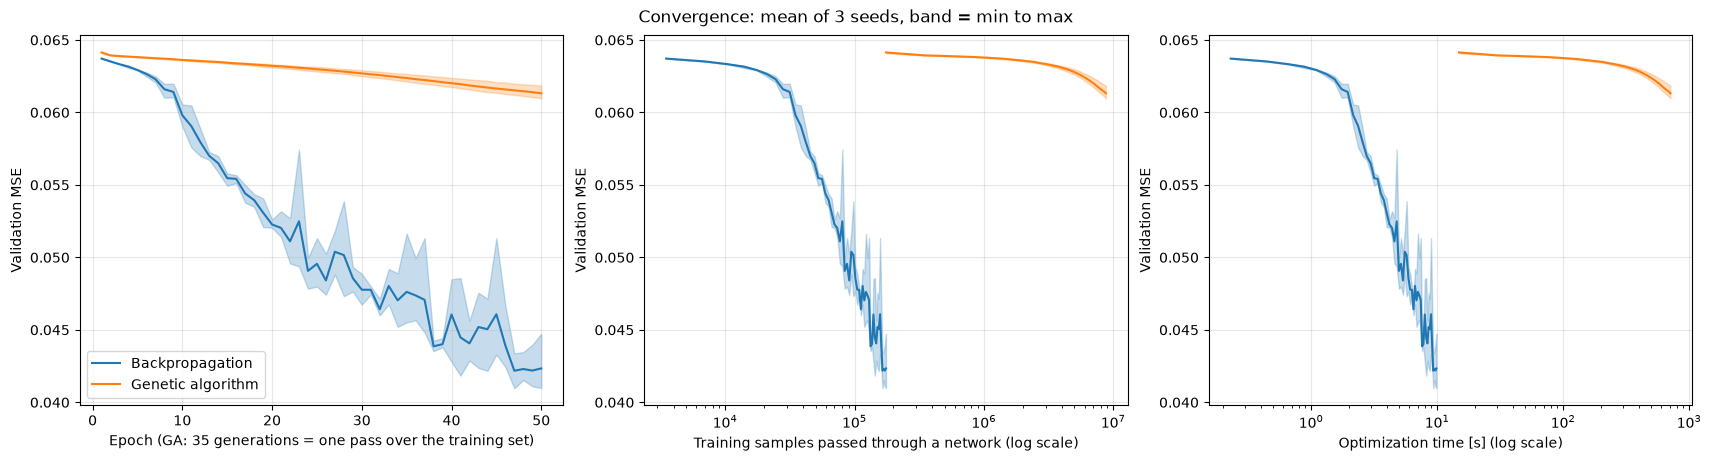

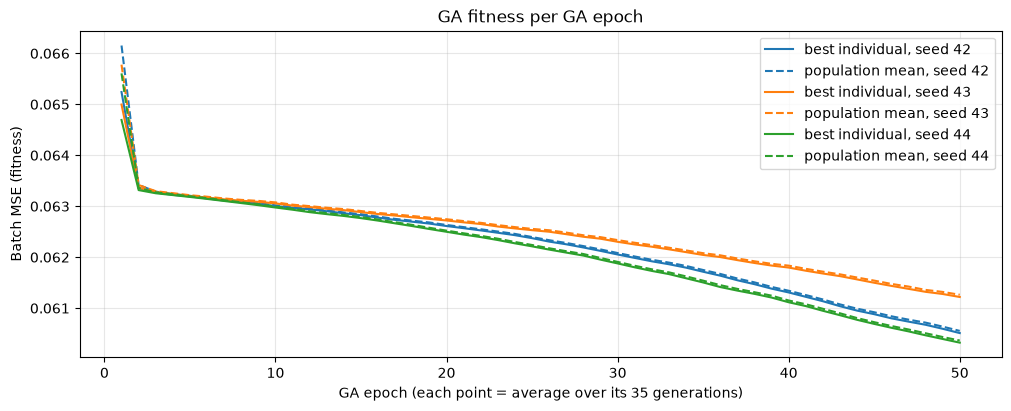


Final errors over seeds [42, 43, 44] (mean ± std):
Method                        train MSE              val MSE             test MSE   time [s]
Backpropagation    0.041909 ± 0.001696 0.042339 ± 0.001697 0.043786 ± 0.001666        9.9
Genetic algorithm  0.060664 ± 0.000391 0.061319 ± 0.000377 0.062205 ± 0.000325      709.3
Backpropagation: reaches the best mean GA validation MSE (0.061319) at epoch 10
Genetic algorithm: reaches the best mean GA validation MSE (0.061319) at epoch 50


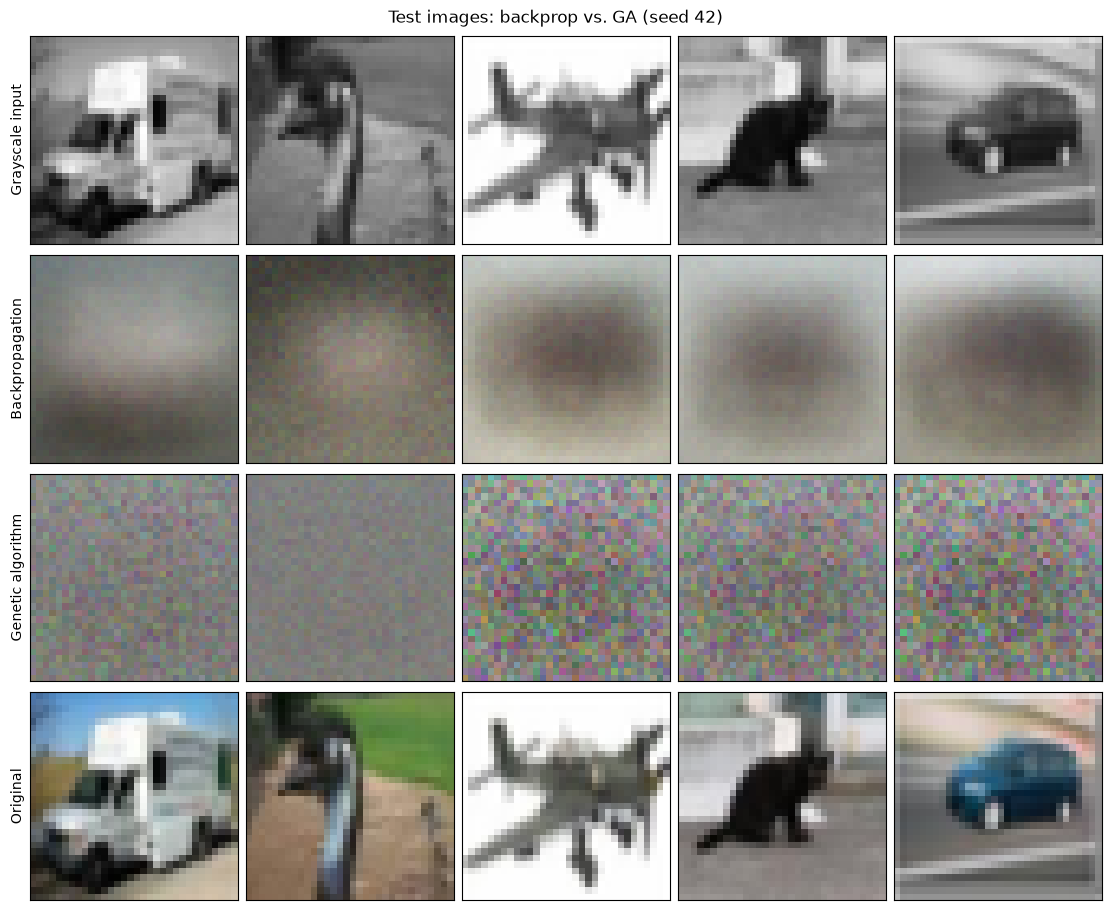

In [4]:
#Task 5
#Genetic Algorithm Comparison
#Optimize the weights of the Task 2/3 network with a genetic algorithm instead of backpropagation, then compare both methods on convergence speed, final error, and stability.

import time

# -----------------------------------------------------------------------------
# 1. Shared setup: same network, same data split, same error function as Task 3
# -----------------------------------------------------------------------------
# The GA optimizes exactly the network that Task 3 trains with backpropagation:
# Colorizer from Task 2 with HIDDEN_SIZE ReLU hidden units and a sigmoid output layer.
# Fitness is Task 3's mean_squared_error, so both methods minimize the same quantity.
mse = TrainableColorizer.mean_squared_error
RUN_SEEDS = [SEED, SEED + 1, SEED + 2]       # three independent runs per method, for stability
N_BATCHES = len(X_train) // BATCH_SIZE       # 35 batches = one full pass over the training set
INPUT_SIZE, OUTPUT_SIZE = X_train.shape[1], Y_train.shape[1]

# An individual is ONE flat vector that holds every weight and bias of the network.
# PARAM_NAMES fixes the order in which the four arrays are concatenated into that vector.
PARAM_NAMES = ['hidden_weights', 'hidden_bias', 'output_weights', 'output_bias']
template = Colorizer(INPUT_SIZE, OUTPUT_SIZE, hidden_size=HIDDEN_SIZE, seed=SEED)
PARAM_SHAPES = [getattr(template, name).shape for name in PARAM_NAMES]
PARAM_SIZES = [int(np.prod(shape)) for shape in PARAM_SHAPES]
N_GENES = sum(PARAM_SIZES)


def flatten(model):
    # Concatenate all weight matrices and bias vectors into one gene vector (the chromosome).
    return np.concatenate([getattr(model, name).ravel() for name in PARAM_NAMES])


def unflatten(genes, model):
    # Write a gene vector back into a Colorizer: each slice becomes a view with the original shape.
    start = 0
    for name, shape, size in zip(PARAM_NAMES, PARAM_SHAPES, PARAM_SIZES):
        setattr(model, name, genes[start:start + size].reshape(shape))
        start += size
    return model


# Round trip check: flatten -> unflatten rebuilds a network with exactly the same output.
rebuilt = unflatten(flatten(template).copy(), Colorizer(INPUT_SIZE, OUTPUT_SIZE, HIDDEN_SIZE, seed=0))
assert N_GENES == INPUT_SIZE * HIDDEN_SIZE + HIDDEN_SIZE + HIDDEN_SIZE * OUTPUT_SIZE + OUTPUT_SIZE
assert np.array_equal(rebuilt.forward(X_val[:5]), template.forward(X_val[:5]))
print(f'Network {INPUT_SIZE}-{HIDDEN_SIZE}-{OUTPUT_SIZE}: {N_GENES:,} genes per individual')


# -----------------------------------------------------------------------------
# 2. Backpropagation baseline: Task 3's training loop, run with several seeds
# -----------------------------------------------------------------------------
def run_backprop(seed):
    # Same steps and hyperparameters as the Task 3 cell (learning_rate, epochs, BATCH_SIZE),
    # wrapped in a function so the identical procedure can be repeated with other seeds.
    model = TrainableColorizer(INPUT_SIZE, OUTPUT_SIZE, hidden_size=HIDDEN_SIZE, seed=seed)
    shuffle_rng = np.random.default_rng(seed)
    history = {'train': [], 'val': [], 'samples': [], 'seconds': []}
    samples, seconds = 0, 0.0
    for epoch in range(epochs):
        start = time.perf_counter()
        permutation = shuffle_rng.permutation(len(X_train))     # reshuffle once per epoch
        inputs, targets = X_train[permutation], Y_train[permutation]
        for b in range(0, len(inputs), BATCH_SIZE):
            batch_inputs = inputs[b:b + BATCH_SIZE]
            batch_targets = targets[b:b + BATCH_SIZE]
            _, cache = model.forward_with_cache(batch_inputs)   # forward
            gradients = model.backward(batch_targets, cache)    # backward
            model.apply_gradients(gradients, learning_rate)     # update
            samples += len(batch_inputs)
        seconds += time.perf_counter() - start                  # optimization time only, no monitoring
        # Monitoring after each epoch: full training and validation error.
        history['train'].append(evaluate(model, X_train, Y_train))
        history['val'].append(evaluate(model, X_val, Y_val))
        history['samples'].append(samples)
        history['seconds'].append(seconds)
    history['test'] = evaluate(model, X_test, Y_test)           # test set used once, at the end
    return model, history


# -----------------------------------------------------------------------------
# 3. Genetic algorithm
# -----------------------------------------------------------------------------
# Hyperparameters (reasons in the report):
POPULATION_SIZE = 50     # individuals per generation
TOURNAMENT_SIZE = 3      # contenders per tournament selection
ELITE_COUNT = 2          # best individuals copied unchanged into the next generation
MUTATION_RATE = 0.01     # probability that a single gene is mutated
MUTATION_STD = 0.02      # standard deviation of the Gaussian mutation noise
GA_EPOCHS = 50           # 1 GA epoch = 35 generations = every training image seen once
GENERATIONS = GA_EPOCHS * N_BATCHES


def population_fitness(population, batch_inputs, batch_targets, network):
    # Fitness of every individual = MSE of its network on the current training batch (lower is better).
    return np.array([mse(unflatten(genes, network).forward(batch_inputs), batch_targets)
                     for genes in population])


def tournament_select(fitness, rng):
    # Tournament selection: pick TOURNAMENT_SIZE random individuals, the one with the lowest MSE wins.
    contenders = rng.integers(0, len(fitness), TOURNAMENT_SIZE)
    return contenders[np.argmin(fitness[contenders])]


def uniform_crossover(parent_a, parent_b, rng):
    # Uniform crossover: every gene is inherited from parent A or parent B with probability 0.5.
    take_from_a = rng.random(N_GENES) < 0.5
    return np.where(take_from_a, parent_a, parent_b)


def gaussian_mutation(genes, rng):
    # Gaussian mutation: about MUTATION_RATE of all genes get a small random offset.
    n_mutated = rng.binomial(N_GENES, MUTATION_RATE)
    positions = rng.choice(N_GENES, n_mutated, replace=False)
    genes[positions] += rng.normal(0, MUTATION_STD, n_mutated)
    return genes


def run_ga(seed):
    rng = np.random.default_rng(seed)
    # Reusable container network. TrainableColorizer is used only because Task 3's evaluate() calls its
    # mean_squared_error method: forward pass and initialization are Task 2's, backward() is never called.
    network = TrainableColorizer(INPUT_SIZE, OUTPUT_SIZE, hidden_size=HIDDEN_SIZE, seed=seed)
    # Initial population: each individual is a fresh network with Task 2's own initialization.
    init_seeds = rng.integers(0, 2**31 - 1, POPULATION_SIZE)
    population = np.stack([flatten(Colorizer(INPUT_SIZE, OUTPUT_SIZE, HIDDEN_SIZE, seed=int(s)))
                           for s in init_seeds])
    history = {'train': [], 'val': [], 'samples': [], 'seconds': [], 'best_fitness': [], 'mean_fitness': []}
    samples, seconds = 0, 0.0
    start = time.perf_counter()
    for generation in range(GENERATIONS):
        batch_index = generation % N_BATCHES
        if batch_index == 0:
            # New GA epoch: reshuffle the training set, exactly like backprop does per epoch.
            permutation = rng.permutation(len(X_train))
            inputs, targets = X_train[permutation], Y_train[permutation]
        batch_inputs = inputs[batch_index * BATCH_SIZE:(batch_index + 1) * BATCH_SIZE]
        batch_targets = targets[batch_index * BATCH_SIZE:(batch_index + 1) * BATCH_SIZE]

        # Evaluation: all individuals are scored on the same batch, so their fitness is comparable.
        fitness = population_fitness(population, batch_inputs, batch_targets, network)
        samples += POPULATION_SIZE * len(batch_inputs)
        history['best_fitness'].append(fitness.min())
        history['mean_fitness'].append(fitness.mean())

        # Replacement: generational, with elitism.
        # The ELITE_COUNT best individuals survive unchanged, the rest of the new
        # generation is filled with children of tournament-selected parents.
        next_population = np.empty_like(population)
        next_population[:ELITE_COUNT] = population[np.argsort(fitness)[:ELITE_COUNT]]
        for child in range(ELITE_COUNT, POPULATION_SIZE):
            parent_a = population[tournament_select(fitness, rng)]
            parent_b = population[tournament_select(fitness, rng)]
            next_population[child] = gaussian_mutation(uniform_crossover(parent_a, parent_b, rng), rng)
        population = next_population

        if batch_index == N_BATCHES - 1:
            # End of a GA epoch: monitor the current best individual (elite 0) on the full sets.
            seconds += time.perf_counter() - start               # optimization time only, no monitoring
            best = unflatten(population[0], network)
            history['train'].append(evaluate(best, X_train, Y_train))
            history['val'].append(evaluate(best, X_val, Y_val))
            history['samples'].append(samples)
            history['seconds'].append(seconds)
            start = time.perf_counter()
    # Final GA model = best individual of the last generation; test set used once, at the end.
    best_model = unflatten(population[0].copy(), TrainableColorizer(INPUT_SIZE, OUTPUT_SIZE, HIDDEN_SIZE, seed=seed))
    history['test'] = evaluate(best_model, X_test, Y_test)
    return best_model, history


# -----------------------------------------------------------------------------
# 4. Run both methods with the same seeds
# -----------------------------------------------------------------------------
bp_models, bp_runs, ga_models, ga_runs = [], [], [], []
for seed in RUN_SEEDS:
    model_bp, history_bp = run_backprop(seed)
    bp_models.append(model_bp)
    bp_runs.append(history_bp)
    print(f'Backprop seed {seed}: val MSE {history_bp["val"][-1]:.6f}, test MSE {history_bp["test"]:.6f}, '
          f'{history_bp["seconds"][-1]:.1f} s')
    model_ga, history_ga = run_ga(seed)
    ga_models.append(model_ga)
    ga_runs.append(history_ga)
    print(f'GA       seed {seed}: val MSE {history_ga["val"][-1]:.6f}, test MSE {history_ga["test"]:.6f}, '
          f'{history_ga["seconds"][-1]:.1f} s')

# The backprop run with SEED repeats the Task 3 cell step by step, so its curve must match Task 3's.
assert np.allclose(bp_runs[0]['train'], training_errors) and np.allclose(bp_runs[0]['val'], validation_errors)


# -----------------------------------------------------------------------------
# 5. Comparison: convergence speed, final error, stability
# -----------------------------------------------------------------------------
def curves(runs, key):
    # Stack one metric of all runs into an array of shape (runs, epochs).
    return np.array([run[key] for run in runs])


epoch_axis = np.arange(1, epochs + 1)
ga_epoch_axis = np.arange(1, GA_EPOCHS + 1)
methods = [('Backpropagation', bp_runs, epoch_axis, 'tab:blue'),
           ('Genetic algorithm', ga_runs, ga_epoch_axis, 'tab:orange')]

# Figure 1: validation MSE against three budget axes (mean over seeds, band = min to max).
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), constrained_layout=True)
for name, runs, x_epochs, color in methods:
    val = curves(runs, 'val')
    for ax, x in zip(axes, [x_epochs, curves(runs, 'samples').mean(axis=0), curves(runs, 'seconds').mean(axis=0)]):
        ax.plot(x, val.mean(axis=0), color=color, label=name)
        ax.fill_between(x, val.min(axis=0), val.max(axis=0), color=color, alpha=0.25)
axes[0].set_xlabel('Epoch (GA: 35 generations = one pass over the training set)')
axes[1].set_xlabel('Training samples passed through a network (log scale)')
axes[1].set_xscale('log')
axes[2].set_xlabel('Optimization time [s] (log scale)')
axes[2].set_xscale('log')
for ax in axes:
    ax.set_ylabel('Validation MSE')
    ax.grid(alpha=0.3)
axes[0].legend()
fig.suptitle(f'Convergence: mean of {len(RUN_SEEDS)} seeds, band = min to max')
plt.show()

# Figure 2: GA fitness (batch MSE) of the best individual and of the population mean.
# Each generation is scored on a different batch, so the raw values jump with the batch difficulty.
# Averaging over the 35 generations of one GA epoch removes that batch noise and shows the trend.
def per_ga_epoch(values):
    return np.asarray(values).reshape(GA_EPOCHS, N_BATCHES).mean(axis=1)


fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
for run, seed in zip(ga_runs, RUN_SEEDS):
    ax.plot(ga_epoch_axis, per_ga_epoch(run['best_fitness']), label=f'best individual, seed {seed}')
    ax.plot(ga_epoch_axis, per_ga_epoch(run['mean_fitness']), linestyle='--', color=ax.lines[-1].get_color(),
            label=f'population mean, seed {seed}')
ax.set_xlabel('GA epoch (each point = average over its 35 generations)')
ax.set_ylabel('Batch MSE (fitness)')
ax.set_title('GA fitness per GA epoch')
ax.grid(alpha=0.3)
ax.legend()
plt.show()

# Table: final training, validation and test MSE, mean and standard deviation over seeds.
print(f'\nFinal errors over seeds {RUN_SEEDS} (mean ± std):')
print(f'{"Method":<18} {"train MSE":>20} {"val MSE":>20} {"test MSE":>20} {"time [s]":>10}')
for name, runs, _, _ in methods:
    final_train = curves(runs, 'train')[:, -1]
    final_val = curves(runs, 'val')[:, -1]
    final_test = np.array([run['test'] for run in runs])
    final_time = curves(runs, 'seconds')[:, -1]
    print(f'{name:<18} {final_train.mean():.6f} ± {final_train.std():.6f} '
          f'{final_val.mean():.6f} ± {final_val.std():.6f} '
          f'{final_test.mean():.6f} ± {final_test.std():.6f} {final_time.mean():>10.1f}')

# Convergence speed: first epoch in which each method reaches a common validation error level.
target = curves(ga_runs, 'val').mean(axis=0).min()
for name, runs, x_epochs, _ in methods:
    reached = np.flatnonzero(curves(runs, 'val').mean(axis=0) <= target)
    when = f'epoch {x_epochs[reached[0]]}' if len(reached) else 'never'
    print(f'{name}: reaches the best mean GA validation MSE ({target:.6f}) at {when}')

# Figure 3: five test images, grayscale input, both outputs and the true color image (seed SEED models).
examples = np.arange(5)
rows = [('Grayscale input', None), ('Backpropagation', bp_models[0]),
        ('Genetic algorithm', ga_models[0]), ('Original', None)]
fig, axes = plt.subplots(4, len(examples), figsize=(2.2 * len(examples), 9), constrained_layout=True)
for column, i in enumerate(examples):
    gray = X_test[i].reshape(IMAGE_SIZE, IMAGE_SIZE)
    images = [gray,
              bp_models[0].forward(X_test[i:i + 1]).reshape(IMAGE_SIZE, IMAGE_SIZE, 3),
              ga_models[0].forward(X_test[i:i + 1]).reshape(IMAGE_SIZE, IMAGE_SIZE, 3),
              Y_test[i].reshape(IMAGE_SIZE, IMAGE_SIZE, 3)]
    for row, ((title, _), image) in enumerate(zip(rows, images)):
        axes[row, column].imshow(image, cmap='gray' if row == 0 else None, vmin=0, vmax=1)
        axes[row, column].set_xticks([])
        axes[row, column].set_yticks([])
        if column == 0:
            axes[row, column].set_ylabel(title)
fig.suptitle(f'Test images: backprop vs. GA (seed {SEED})')
plt.show()